# Integrated Case Study: Student Learning Analytics

This final chapter integrates several multivariate methods into one analytical story.

# 総合ケーススタディ：学生の学習データ分析

この最終章では、これまで学んだ多変量解析を1つのデータセットに対して使い分けます。

> Start from the analytical question, then choose the method.

> 「手法ありき」ではなく、「何を知りたいか」から分析手法を選ぶ。

これが本章の中心テーマです。

## 1. Learning Objectives / 学習目標

- Build an analysis workflow from analytical questions
- Select methods according to objectives
- Use PCA for dimensionality reduction
- Use Cluster Analysis for segmentation
- Use Multiple Regression for a continuous outcome
- Use Logistic Regression for classification
- Use MANOVA for multivariate group comparison
- Integrate results into one interpretation
- Recognize that not every learned method must be used

- 分析課題から分析フローを設計する
- 目的に応じて手法を選択する
- PCAで次元削減する
- クラスター分析でセグメント化する
- 重回帰で連続値を分析する
- ロジスティック回帰で分類する
- MANOVAで複数成果を同時比較する
- 複数手法の結果を統合する
- 学んだ手法を全部使う必要はないことを理解する

## 2. Scenario / シナリオ

A university has learning-behavior, psychological, and achievement data.

The analytics team asks:

1. Can many learning variables be summarized?
2. Are there meaningful student profiles?
3. Which factors are associated with academic achievement?
4. Can high-achievement students be classified?
5. Do academic programs differ across several outcomes?

大学の学生データを使い、「データを見る → 問いを立てる → 手法を選ぶ → 結果を統合する」という分析者の流れを体験します。

## 3. Method Selection Map / 分析目的と手法

| Question | Method | Purpose |
|---|---|---|
| Summarize correlated variables | PCA | Dimensionality reduction |
| Find student profiles | Cluster Analysis | Unsupervised segmentation |
| Explain average achievement | Multiple Regression | Continuous outcome |
| Classify high achievement | Logistic Regression | Binary outcome |
| Compare several outcomes by program | MANOVA | Multivariate group comparison |

この章では「分析課題 → 手法」という順番を崩さないことが重要です。

## 4. Import Libraries / ライブラリの読み込み

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.multivariate.manova import MANOVA
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
pd.set_option("display.max_columns",None)

## 5. Load and Understand the Dataset / データの読み込みと確認

In [2]:
paths=[Path("../data/student_learning_analytics.csv"),Path("14_integrated_case_study/data/student_learning_analytics.csv"),Path("data/student_learning_analytics.csv")]
data_path=next((p for p in paths if p.exists()),None)
if data_path is None: raise FileNotFoundError("student_learning_analytics.csv was not found.")
df=pd.read_csv(data_path)
df.head()

,student_id,program,sleep_hours,attendance_rate,study_hours_week,assignment_completion_rate,self_efficacy,stress_score,math_score,reading_score,problem_solving_score
0,S001,Humanities,6.66,86.04,4.34,85.18,56.91,51.51,65.11,83.35,71.42
1,S002,STEM,7.56,84.79,12.53,90.57,79.90,45.35,97.59,79.02,100.00
2,S003,Humanities,7.95,82.40,4.68,77.35,58.82,49.59,69.37,79.07,74.76
3,S004,STEM,7.17,99.03,12.94,93.51,78.92,36.60,96.36,90.88,84.33
4,S005,General,6.54,82.00,9.05,83.66,57.05,47.12,82.04,77.35,82.40


In [4]:
print("Shape:",df.shape)
df.info()

Shape: (360, 11)
<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  360 non-null    str    
 1   program                     360 non-null    str    
 2   sleep_hours                 360 non-null    float64
 3   attendance_rate             360 non-null    float64
 4   study_hours_week            360 non-null    float64
 5   assignment_completion_rate  360 non-null    float64
 6   self_efficacy               360 non-null    float64
 7   stress_score                360 non-null    float64
 8   math_score                  360 non-null    float64
 9   reading_score               360 non-null    float64
 10  problem_solving_score       360 non-null    float64
dtypes: float64(9), str(2)
memory usage: 31.1 KB


In [3]:
df.isna().sum()

student_id                    0
program                       0
sleep_hours                   0
attendance_rate               0
study_hours_week              0
assignment_completion_rate    0
self_efficacy                 0
stress_score                  0
math_score                    0
reading_score                 0
problem_solving_score         0
dtype: int64

In [5]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,360,360,S001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
program,360,3,General,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sleep_hours,360.0,NaN,NaN,NaN,6.736417,0.82223,4.5,6.19,6.74,7.27,9.0
attendance_rate,360.0,NaN,NaN,NaN,86.276194,6.667411,67.37,81.555,86.465,90.61,100.0
study_hours_week,360.0,NaN,NaN,NaN,8.345611,2.96002,2.0,6.36,8.415,10.315,17.26
assignment_completion_rate,360.0,NaN,NaN,NaN,83.863639,8.138528,60.34,78.5425,84.265,89.75,100.0
self_efficacy,360.0,NaN,NaN,NaN,64.941361,9.652109,39.44,58.06,65.065,71.52,88.15
stress_score,360.0,NaN,NaN,NaN,50.241472,9.643842,20.16,44.1075,50.39,56.36,80.44
math_score,360.0,NaN,NaN,NaN,83.184278,10.783531,46.8,76.2925,83.715,91.37,100.0
reading_score,360.0,NaN,NaN,NaN,82.285167,9.230957,48.67,76.7275,83.325,88.6775,100.0


## 6. Create an Overall Achievement Measure / 総合成績を作る

For exploratory and regression purposes, calculate the mean of the three achievement scores.

The original scores remain available for MANOVA.

探索・回帰用に3科目平均を作りますが、MANOVAでは元の3科目を使用します。

In [6]:
scores=["math_score","reading_score","problem_solving_score"]
df["average_score"]=df[scores].mean(axis=1)
df[scores+["average_score"]].describe().round(2)

,math_score,reading_score,problem_solving_score,average_score
count,360.00,360.00,360.00,360.00
mean,83.18,82.29,81.24,82.24
std,10.78,9.23,10.56,9.25
min,46.80,48.67,46.60,50.21
25%,76.29,76.73,74.32,76.42
50%,83.72,83.32,82.08,83.06
75%,91.37,88.68,88.51,88.63
max,100.00,100.00,100.00,100.00


## 7. Correlation Structure / 相関構造

In [7]:
numeric=["sleep_hours","attendance_rate","study_hours_week","assignment_completion_rate","self_efficacy","stress_score","math_score","reading_score","problem_solving_score"]
corr=df[numeric].corr()
corr.round(2)

,sleep_hours,attendance_rate,study_hours_week,assignment_completion_rate,self_efficacy,stress_score,math_score,reading_score,problem_solving_score
sleep_hours,1.00,0.15,0.04,-0.15,0.06,-0.48,-0.03,0.01,-0.03
attendance_rate,0.15,1.00,0.53,0.56,0.45,-0.38,0.24,0.21,0.25
study_hours_week,0.04,0.53,1.00,0.63,0.58,-0.21,0.53,0.51,0.55
assignment_completion_rate,-0.15,0.56,0.63,1.00,0.57,-0.13,0.46,0.45,0.52
self_efficacy,0.06,0.45,0.58,0.57,1.00,-0.21,0.76,0.73,0.78
stress_score,-0.48,-0.38,-0.21,-0.13,-0.21,1.00,-0.11,-0.08,-0.11
math_score,-0.03,0.24,0.53,0.46,0.76,-0.11,1.00,0.68,0.78
reading_score,0.01,0.21,0.51,0.45,0.73,-0.08,0.68,1.00,0.74
problem_solving_score,-0.03,0.25,0.55,0.52,0.78,-0.11,0.78,0.74,1.00


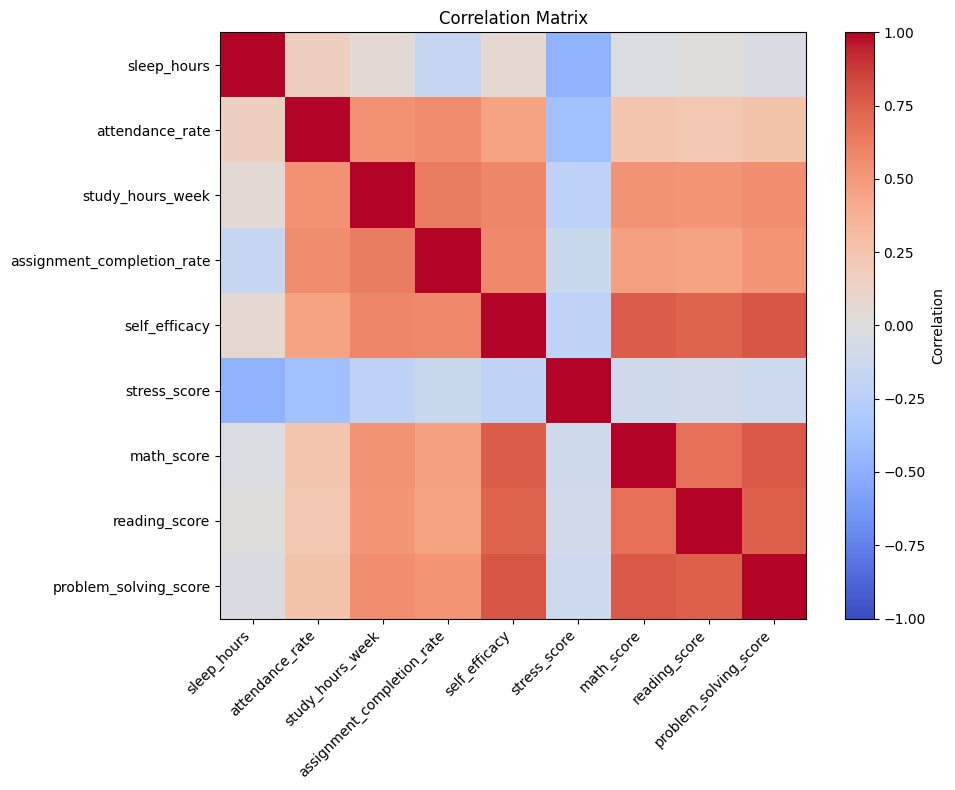

In [8]:
fig,ax=plt.subplots(figsize=(10,8))
im=ax.imshow(corr.values,vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(range(len(numeric)),labels=numeric,rotation=45,ha="right")
ax.set_yticks(range(len(numeric)),labels=numeric)
fig.colorbar(im,ax=ax,label="Correlation")
ax.set_title("Correlation Matrix")
plt.tight_layout(); plt.show()

# Part 1 — PCA / 主成分分析

## 8. Question: Can Learning Variables Be Summarized? / 学習関連変数を要約できるか

Several predictors are correlated. PCA can summarize them into a smaller number of dimensions.

複数の学習関連変数を少数の軸に要約するため、PCAを使います。

In [9]:
pca_features=["sleep_hours","attendance_rate","study_hours_week","assignment_completion_rate","self_efficacy","stress_score"]
X_scaled=StandardScaler().fit_transform(df[pca_features])
pca=PCA()
pca_scores=pca.fit_transform(X_scaled)
explained=pd.DataFrame({
"component":[f"PC{i+1}" for i in range(len(pca_features))],
"explained_variance_ratio":pca.explained_variance_ratio_,
"cumulative_ratio":np.cumsum(pca.explained_variance_ratio_)})
explained.round(3)

,component,explained_variance_ratio,cumulative_ratio
0,PC1,0.467,0.467
1,PC2,0.244,0.711
2,PC3,0.097,0.808
3,PC4,0.076,0.883
4,PC5,0.065,0.948
5,PC6,0.052,1.000


In [10]:
loadings=pd.DataFrame(pca.components_.T,index=pca_features,columns=[f"PC{i+1}" for i in range(len(pca_features))])
loadings.iloc[:,:3].round(3)

,PC1,PC2,PC3
sleep_hours,0.100,0.714,0.422
attendance_rate,0.477,0.079,-0.525
study_hours_week,0.493,-0.141,0.205
assignment_completion_rate,0.479,-0.309,-0.155
self_efficacy,0.464,-0.118,0.597
stress_score,-0.274,-0.596,0.350


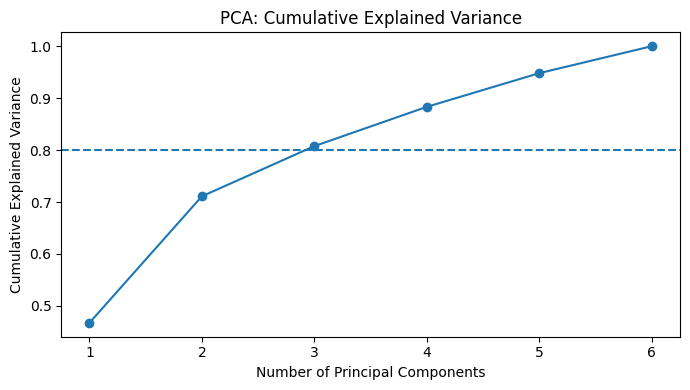

In [11]:
plt.figure(figsize=(7,4))
plt.plot(range(1,len(pca_features)+1),np.cumsum(pca.explained_variance_ratio_),marker="o")
plt.axhline(.80,linestyle="--")
plt.xlabel("Number of Principal Components"); plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Cumulative Explained Variance"); plt.xticks(range(1,len(pca_features)+1))
plt.tight_layout(); plt.show()

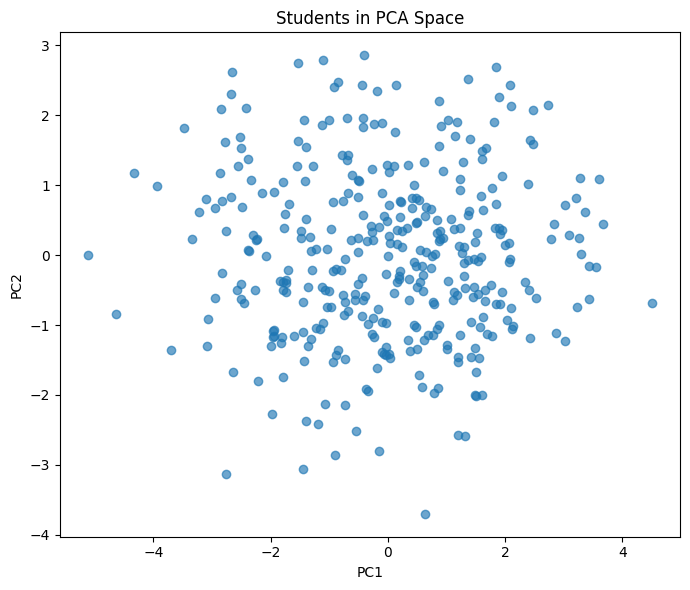

In [12]:
df["PC1"]=pca_scores[:,0]; df["PC2"]=pca_scores[:,1]
plt.figure(figsize=(7,6)); plt.scatter(df["PC1"],df["PC2"],alpha=.65)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Students in PCA Space")
plt.tight_layout(); plt.show()

# Part 2 — Cluster Analysis / クラスター分析

## 9. Question: Are There Student Profiles? / 学生タイプは存在するか

There is no target label. Cluster Analysis is therefore appropriate.

正解ラベルのないセグメンテーションなので、クラスター分析を使います。

In [13]:
cluster_X=df[["PC1","PC2"]]
rows=[]
for k in range(2,8):
    km=KMeans(n_clusters=k,random_state=42,n_init=20).fit(cluster_X)
    rows.append([k,km.inertia_,silhouette_score(cluster_X,km.labels_)])
cluster_diagnostics=pd.DataFrame(rows,columns=["k","inertia","silhouette"])
cluster_diagnostics.round(3)

,k,inertia,silhouette
0,2,865.288,0.379
1,3,642.868,0.332
2,4,491.201,0.336
3,5,392.333,0.341
4,6,337.045,0.334
5,7,286.917,0.346


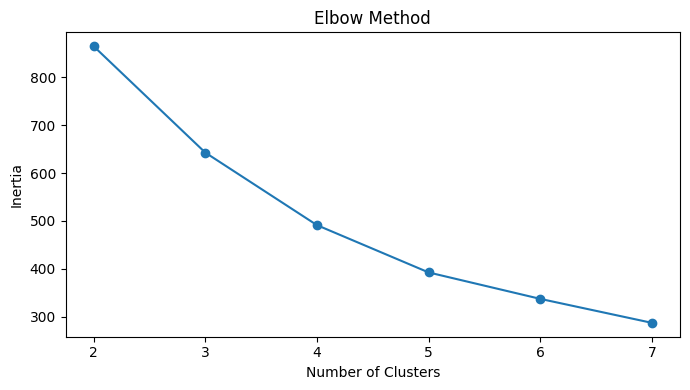

In [14]:
plt.figure(figsize=(7,4))
plt.plot(cluster_diagnostics["k"],cluster_diagnostics["inertia"],marker="o")
plt.xlabel("Number of Clusters"); plt.ylabel("Inertia"); plt.title("Elbow Method")
plt.tight_layout(); plt.show()

For this educational case study, use three clusters and then interpret them using the original variables.

ここでは3クラスターを採用し、元の変数へ戻って特徴を解釈します。

In [15]:
kmeans=KMeans(n_clusters=3,random_state=42,n_init=20)
df["cluster"]=kmeans.fit_predict(cluster_X)
df["cluster"].value_counts().sort_index()

cluster
0    119
1     95
2    146
Name: count, dtype: int64

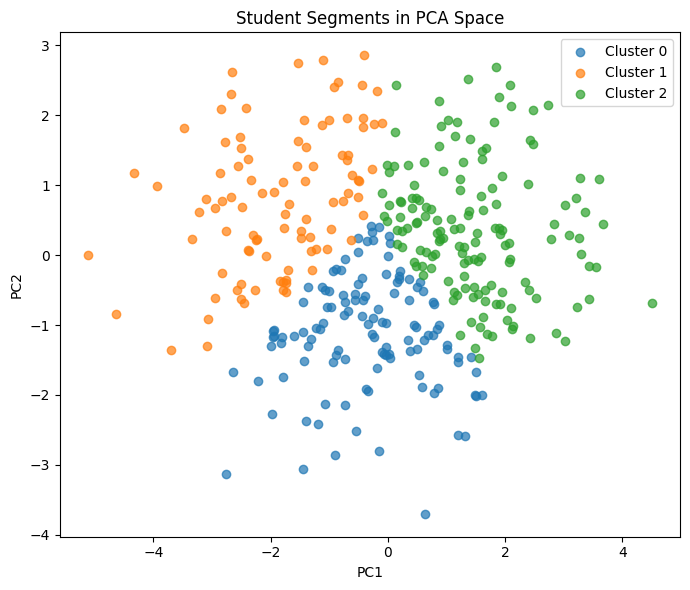

In [16]:
plt.figure(figsize=(7,6))
for c in sorted(df["cluster"].unique()):
    s=df[df["cluster"]==c]
    plt.scatter(s["PC1"],s["PC2"],label=f"Cluster {c}",alpha=.7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Student Segments in PCA Space")
plt.legend(); plt.tight_layout(); plt.show()

In [17]:
profile=["sleep_hours","attendance_rate","study_hours_week","assignment_completion_rate","self_efficacy","stress_score","average_score"]
df.groupby("cluster")[profile].mean().round(2)

,sleep_hours,attendance_rate,study_hours_week,assignment_completion_rate,self_efficacy,stress_score,average_score
cluster,,,,,,,
0,6.06,84.53,8.37,85.68,64.15,57.43,82.68
1,7.03,80.81,5.29,74.63,55.61,50.05,74.04
2,7.10,91.26,10.31,88.39,71.66,44.51,87.21


# Part 3 — Multiple Regression / 重回帰分析

## 10. Question: What Is Associated with Achievement? / 成績と関連する要因は何か

Average score is continuous, so Multiple Regression is appropriate.

平均成績という連続値を目的変数として、学習要因との関連を分析します。

In [18]:
features=["sleep_hours","attendance_rate","study_hours_week","assignment_completion_rate","self_efficacy","stress_score"]
X=df[features]; y=df["average_score"]
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,random_state=42)
m=sm.OLS(ytr,sm.add_constant(Xtr)).fit()
print(m.summary())

                            OLS Regression Results                            
Dep. Variable:          average_score   R-squared:                       0.765
Model:                            OLS   Adj. R-squared:                  0.759
Method:                 Least Squares   F-statistic:                     142.3
Date:                   土, 03 10 2026   Prob (F-statistic):           1.34e-79
Time:                        19:41:27   Log-Likelihood:                -783.50
No. Observations:                 270   AIC:                             1581.
Df Residuals:                     263   BIC:                             1606.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

In [19]:
pred=m.predict(sm.add_constant(Xte,has_constant="add"))
print(f"Test RMSE: {mean_squared_error(yte,pred)**0.5:.3f}")
print(f"Test R²:   {r2_score(yte,pred):.3f}")

Test RMSE: 5.203
Test R²:   0.709


Interpret these coefficients as associations, not automatically as causal effects.

係数は因果効果と断定せず、他の変数を調整した上での関連として解釈します。

# Part 4 — Logistic Regression / ロジスティック回帰

## 11. Question: Can High Achievement Be Classified? / 高成績群を分類できるか

Define the upper quartile of average achievement as the positive class.

平均成績の上位25%をHigh Achievementとして2値分類します。

In [20]:
threshold=df["average_score"].quantile(.75)
df["high_achievement"]=(df["average_score"]>=threshold).astype(int)
print("Threshold:",round(threshold,2))
print(df["high_achievement"].value_counts())

Threshold: 88.63
high_achievement
0    270
1     90
Name: count, dtype: int64


In [21]:
X=df[features]; y=df["high_achievement"]
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
scaler=StandardScaler()
Xtr_s=scaler.fit_transform(Xtr); Xte_s=scaler.transform(Xte)
logit=LogisticRegression(max_iter=1000,random_state=42).fit(Xtr_s,ytr)
yp=logit.predict(Xte_s)
print("Accuracy:",round(accuracy_score(yte,yp),3))
print(classification_report(yte,yp))

Accuracy: 0.844
              precision    recall  f1-score   support

           0       0.89      0.91      0.90        68
           1       0.70      0.64      0.67        22

    accuracy                           0.84        90
   macro avg       0.79      0.77      0.78        90
weighted avg       0.84      0.84      0.84        90



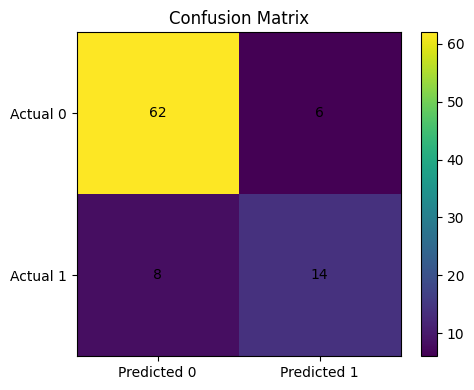

In [22]:
cm=confusion_matrix(yte,yp)
fig,ax=plt.subplots(figsize=(5,4)); im=ax.imshow(cm)
ax.set_xticks([0,1],labels=["Predicted 0","Predicted 1"])
ax.set_yticks([0,1],labels=["Actual 0","Actual 1"])
for i in range(2):
    for j in range(2): ax.text(j,i,cm[i,j],ha="center",va="center")
fig.colorbar(im,ax=ax); ax.set_title("Confusion Matrix")
plt.tight_layout(); plt.show()

# Part 5 — MANOVA / 多変量分散分析

## 12. Question: Do Programs Differ Across Multiple Outcomes? / 学科間で複数の成績に差があるか

Math, Reading, and Problem-Solving scores are related outcomes.

MANOVA tests the program difference across them simultaneously.

数学・読解・問題解決をまとめて、学科による違いを検討します。

In [23]:
manova=MANOVA.from_formula(
"math_score + reading_score + problem_solving_score ~ C(program)",
data=df)
print(manova.mv_test())

                   Multivariate linear model
                                                                
----------------------------------------------------------------
       Intercept         Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0278 3.0000 355.0000 4133.3619 0.0000
         Pillai's trace  0.9722 3.0000 355.0000 4133.3619 0.0000
 Hotelling-Lawley trace 34.9298 3.0000 355.0000 4133.3619 0.0000
    Roy's greatest root 34.9298 3.0000 355.0000 4133.3619 0.0000
----------------------------------------------------------------
                                                                
----------------------------------------------------------------
          C(program)       Value  Num DF  Den DF  F Value Pr > F
----------------------------------------------------------------
             Wilks' lambda 0.7386 6.0000 710.0000 19.3542 0.0000
            Pillai's trace 0.2656 6.0000 712.

In [24]:
df.groupby("program")[scores].mean().round(2)

,math_score,reading_score,problem_solving_score
program,,,
General,81.76,81.68,80.94
Humanities,80.24,84.76,80.19
STEM,87.18,81.19,82.41


## 13. Why Not Run Three ANOVAs First? / なぜ最初からANOVAを3回しないのか

The outcomes are correlated.

MANOVA evaluates the multivariate outcome jointly and avoids treating each score as an unrelated problem.

MANOVAで全体差を確認した後、必要に応じて個別分析へ進む、という考え方ができます。

# Part 6 — Integrated Interpretation / 統合的な解釈

## 14. Connect the Results / 分析結果をつなげる

The analyses answer different questions.

- **PCA** summarizes the learning-behavior structure.
- **Cluster Analysis** turns that structure into student profiles.
- **Multiple Regression** examines variables associated with continuous achievement.
- **Logistic Regression** reframes achievement as a classification problem.
- **MANOVA** compares several achievement outcomes across academic programs.

These methods are complementary rather than competitors.

各手法は同じことを別の方法でやっているわけではありません。

「要約」「分類」「説明・予測」「群間比較」という異なる問いに答えています。

## 15. Methods We Did Not Force into the Case / あえて使わなかった手法

The repository also covers:

- Factor Analysis
- Discriminant Analysis
- Canonical Correlation Analysis
- Correspondence Analysis
- Multidimensional Scaling
- Partial Least Squares
- Path Analysis
- Structural Equation Modeling

They are valuable methods, but the current analytical questions do not require all of them.

A mature analyst does **not** use a method simply because it has been learned.

これが総合章で特に大切なポイントです。

> 「使える手法を全部使う」のではなく、「問いに必要な手法だけを選ぶ」。

多変量解析では、手法選択そのものが分析スキルです。

## 16. A Practical Decision Guide / 実務での手法選択ガイド

Ask these questions:

1. What is the analytical objective?
2. Is there a target variable?
3. Is the target continuous, categorical, or multivariate?
4. Are we explaining, predicting, reducing dimensions, grouping, or testing differences?
5. Are the variables numerical or categorical?
6. Are latent constructs part of the research question?
7. What assumptions does the candidate method require?

分析を始める前に、まずこの問いを整理すると、手法選択がかなり楽になります。

## 17. Limitations / 限界

This case study uses simulated data.

Important limitations include:

- associations do not establish causality
- PCA interpretation can be subjective
- cluster solutions depend on scaling, variables, and the number of clusters
- classification performance depends on the chosen threshold and metric
- regression assumptions require diagnostic checking
- MANOVA has its own assumptions
- results should be validated with new data in real projects

今回の目的は「分析プロセスを統合して理解すること」です。

実務では、データ品質確認・外れ値処理・仮定の検証・モデル検証・再現性確保などをさらに丁寧に行います。

## 18. Final Conclusion / 最終まとめ

This repository began with individual multivariate methods.

The final chapter changes the perspective:

> Do not ask, "Which technique should I practice?"
>
> Ask, "What question am I trying to answer?"

The integrated workflow was:

1. Understand the problem and data
2. Explore relationships
3. Reduce dimensions with PCA
4. Segment observations with Cluster Analysis
5. Explain a continuous outcome with Multiple Regression
6. Classify a binary outcome with Logistic Regression
7. Compare multiple outcomes with MANOVA
8. Integrate the findings
9. State limitations
10. Decide what analysis should come next

このリポジトリの最終的なゴールは、手法名を覚えることではありません。

**「分析目的に応じて、多変量解析を選択し、結果を解釈できること」**

これを14章の到達点とします。